# 02 - Features and time-based validation



## 1. Setup and data

In [14]:
import sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import lightgbm as lgb
from sklearn.model_selection import KFold

from src import config, preprocessing as pp, features as F, splits as S, evaluation as ev

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

def read(path):
    return pd.read_csv(path, parse_dates=["date"])

train = read(config.TRAIN_CLEAN)
outliers = read(config.LABEL_OUTLIERS)
val = read(config.VALIDATION_CLEAN)
train_raw = pp.load_raw(config.TRAIN_RAW)
val_raw = pp.load_raw(config.VALIDATION_RAW)
params = pp.load_params()


def prepare_fold(raw_train, raw_test):
    """Fit imputation and label cleaning on historical rows only."""
    fold_params = pp.fit_params(raw_train)
    fold_line = pp.fit_robust_rate_line(raw_train)
    train_features = pp.clean_features(raw_train, fold_params)
    test_features = pp.clean_features(raw_test, fold_params)
    train_outliers = pp.flag_label_outliers(raw_train, fold_line)
    clean_train = train_features.loc[~train_outliers].reset_index(drop=True)
    clean_test = test_features.reset_index(drop=True)
    return clean_train, clean_test, int(train_outliers.sum())


def prepare_fold_by_masks(raw, train_mask, test_mask):
    return prepare_fold(raw.loc[train_mask], raw.loc[test_mask])

print(train.shape, outliers.shape, val.shape)

(47323, 13) (677, 13) (12000, 12)


## 2. Validation scheme

The real job: learn from **Jan-Oct 2025**, predict **Nov-Dec 2025**. So every check trains on the past and
tests on the next two months, with the same horizon as the real task. Three expanding windows:

| fold | train | test |
|---|---|---|
| A | Jan-Apr | May-Jun |
| B | Jan-Jun | Jul-Aug |
| C (main holdout) | Jan-Aug | Sep-Oct |

In [3]:
rows = []
for name, start, end in S.EXPANDING_FOLDS:
    a, b = S.fold_masks(train, start, end)
    S.assert_no_leakage(train, a, b)          # strictly earlier, no shared ids
    rows.append({"fold": name, "train rows": int(a.sum()), "test rows": int(b.sum()),
                 "train ends": train[a].date.max().date(), "test starts": train[b].date.min().date(),
                 "test ends": train[b].date.max().date()})
pd.DataFrame(rows)

,fold,train rows,test rows,train ends,test starts,test ends
0,A,18835,9571,2025-04-30,2025-05-01,2025-06-30
1,B,28406,9538,2025-06-30,2025-07-01,2025-08-31
2,C,37944,9379,2025-08-31,2025-09-01,2025-10-31


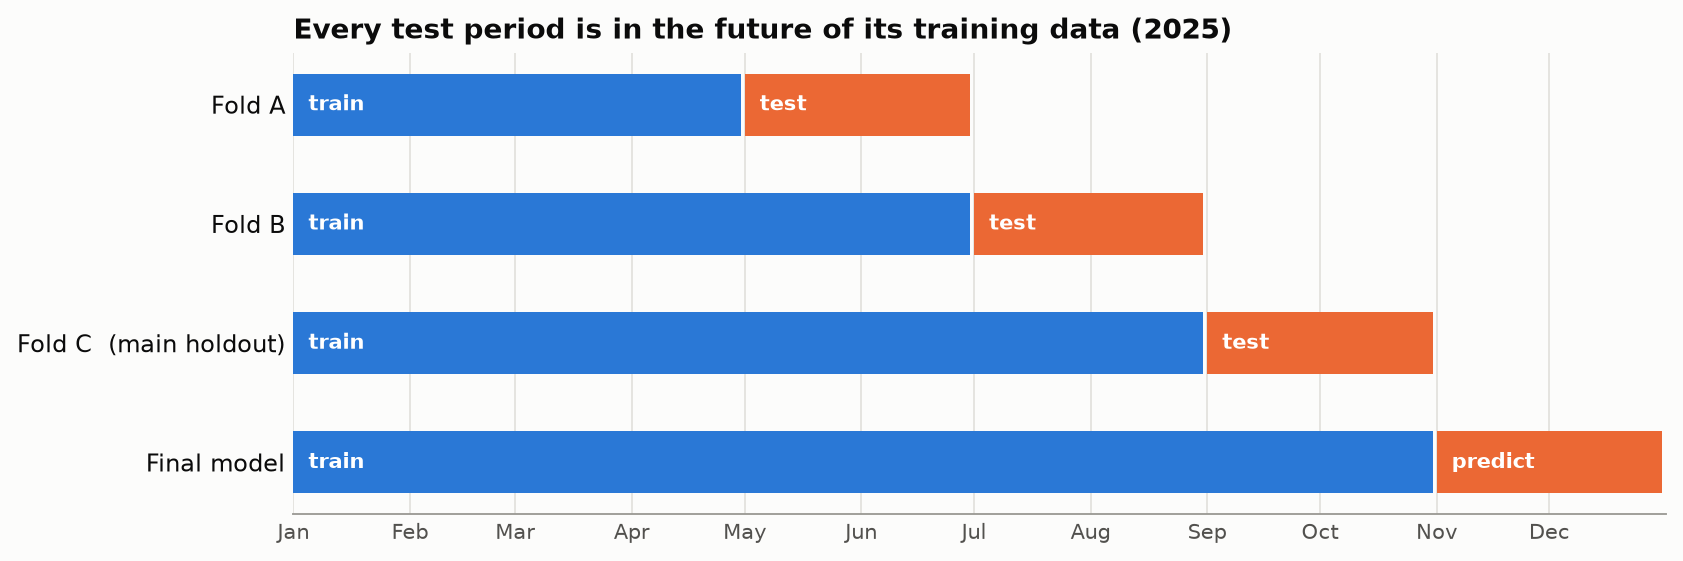

In [4]:
# Figure for the report: the split scheme
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
months = pd.date_range("2025-01-01", "2026-01-01", freq="MS")
x = lambda d: (pd.Timestamp(d) - pd.Timestamp("2025-01-01")).days

bars = [("Fold A", "2025-01-01", "2025-05-01", "2025-07-01"),
        ("Fold B", "2025-01-01", "2025-07-01", "2025-09-01"),
        ("Fold C  (main holdout)", "2025-01-01", "2025-09-01", "2025-11-01"),
        ("Final model", "2025-01-01", "2025-11-01", "2026-01-01")]

fig, ax = plt.subplots(figsize=(10, 3.4), dpi=170)
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
for i, (label, t0, t1, t2) in enumerate(bars):
    y = len(bars) - 1 - i
    ax.barh(y, x(t1) - x(t0) - 1, left=x(t0), height=0.52, color=BLUE)
    ax.barh(y, x(t2) - x(t1) - 1, left=x(t1), height=0.52, color=ORANGE)
    ax.text(x(t0) + 4, y, "train", va="center", color="white", fontsize=9, fontweight="bold")
    ax.text(x(t1) + 4, y, "test" if label != "Final model" else "predict", va="center", color="white", fontsize=9, fontweight="bold")
ax.set_yticks(range(len(bars))); ax.set_yticklabels([b[0] for b in bars][::-1], color=INK, fontsize=10)
ax.set_xticks([x(m) for m in months[:-1]]); ax.set_xticklabels([m.strftime("%b") for m in months[:-1]], color=MUTED, fontsize=9)
ax.set_xlim(0, x("2026-01-01")); ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color("#9d9c97"); ax.tick_params(length=0)
ax.set_title("Every test period is in the future of its training data (2025)", loc="left", fontsize=12, fontweight="bold", color=INK)
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "split_scheme.png", bbox_inches="tight"); plt.show()

### Why not a random split?

In [16]:
# Compare an ordinary shuffled 5-fold CV with the time-based folds, same model and features.
def fit_predict(raw_train_df, raw_test_df, groups):
    clean_train, clean_test, _ = prepare_fold(raw_train_df, raw_test_df)
    model = lgb.LGBMRegressor(**config.LGBM_QUICK_PARAMS)
    model.fit(F.build_features(clean_train, groups), np.log(clean_train[config.TARGET]))
    return np.exp(model.predict(F.build_features(clean_test, groups)))

FINAL = config.FINAL_FEATURE_GROUPS
bad_ids = set(outliers["load_id"])
rand = []
for tr_i, te_i in KFold(5, shuffle=True, random_state=config.RANDOM_STATE).split(train_raw):
    a, b = train_raw.iloc[tr_i], train_raw.iloc[te_i]
    predictions = fit_predict(a, b, FINAL)
    keep = ~b["load_id"].isin(bad_ids).to_numpy()
    rand.append(ev.metrics(b.loc[keep, config.TARGET], predictions[keep]))
rand = pd.DataFrame(rand)

timed = []
for name, start, end in S.EXPANDING_FOLDS:
    a_m, b_m = S.fold_masks(train_raw, start, end)
    a, b = train_raw[a_m], train_raw[b_m]
    predictions = fit_predict(a, b, FINAL)
    keep = ~b["load_id"].isin(bad_ids).to_numpy()
    timed.append({"fold": name, **ev.metrics(b.loc[keep, config.TARGET], predictions[keep])})
timed = pd.DataFrame(timed).set_index("fold")

print("Random 5-fold CV   (clean labels):", rand[["MAE", "MAPE_%"]].mean().round(2).to_dict(),
      "| average bias %:", round(rand["bias_%"].mean(), 2))
print()
print("Time-based folds (clean labels):")
timed.round(2)

Random 5-fold CV   (clean labels): {'MAE': 68.87, 'MAPE_%': 2.94} | average bias %: 0.21

Time-based folds (clean labels):


,MAE,MAPE_%,RMSE,bias_%
fold,,,,
A,146.63,5.86,187.97,-5.83
B,54.38,2.31,78.96,-0.63
C,44.71,1.97,66.16,-0.66


**Finding:** a shuffled 5-fold split reports MAE 68.8 (MAPE 2.9%), but the time-based folds range from 44.5 (C) to 147.1 (A), 82.1 on average. That spread is the real information: when the market level moves between the training months and the test months, error jumps (fold A is biased by -5.9%, because Jan-Apr loads were priced lower than May-Jun ones). A shuffled split puts every month into training, so it cannot show this, and it lets the model learn from loads dated the same days it is scored on. The real task is the time-based situation, so that is how we validate.

## 3. Feature builder

`src/features.build_features` is the single function used for train, validation and the December chart, so the
columns can never drift apart. Only columns present in all three inputs may be used. The December file has no
coordinates, so `add_coordinates` looks them up by city name.

In [6]:
city_table = F.build_city_table(train_raw, val_raw)
dec_raw = pp.load_raw(config.DECEMBER_INPUTS)
dec = F.add_coordinates(pp.clean_features(dec_raw, params), city_table)

X_train = F.build_features(train)
X_val = F.build_features(val)
X_dec = F.build_features(dec)
assert list(X_train.columns) == list(X_val.columns) == list(X_dec.columns)

print("train:", X_train.shape, "| validation:", X_val.shape, "| december:", X_dec.shape)
print("features:", list(X_train.columns))
print()
print("December coordinates came from:", dec[["pickup", "pickup_lat", "pickup_lon", "delivery", "delivery_lat", "delivery_lon"]].drop_duplicates().to_dict("records"))
X_dec.head(3)

train: (47323, 12) | validation: (12000, 12) | december: (31, 12)
features: ['distance', 'log_distance', 'weight', 'weight_missing', 'eq_Dry_Van', 'eq_Flatbed', 'eq_Reefer', 'dow', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon']

December coordinates came from: [{'pickup': 'Lexington', 'pickup_lat': 36.99152, 'pickup_lon': -84.99876, 'delivery': 'Fort Wayne', 'delivery_lat': 41.31561, 'delivery_lon': -85.36206}]


,distance,log_distance,weight,weight_missing,eq_Dry_Van,eq_Flatbed,eq_Reefer,dow,pickup_lat,pickup_lon,delivery_lat,delivery_lon
0,360.0,5.886104,32000.0,0,1,0,0,0,36.99152,-84.99876,41.31561,-85.36206
1,360.0,5.886104,32000.0,0,1,0,0,1,36.99152,-84.99876,41.31561,-85.36206
2,360.0,5.886104,32000.0,0,1,0,0,2,36.99152,-84.99876,41.31561,-85.36206


## 4. Which features? Ablation on the time-based folds

Same LightGBM settings (not tuned) for every row, trained on `log(rate)` so predictions are always positive.
Metric is MAE in dollars on the clean test rows; the reference line is a naive
"median $ per mile by equipment x distance" model.

In [17]:
FEATURE_SETS = {
    "core: distance, weight, equipment":      (),
    "+ day of week":                          ("dow",),
    "+ day of week + month":                  ("dow", "month"),
    "+ day of week + trend (days since Jan 1)": ("dow", "t"),
    "+ day of week + seasonal sin/cos":       ("dow", "doy"),
    "+ day of week + coordinates   [chosen]": ("dow", "coords"),
    "+ day of week + coordinates + trend":    ("dow", "coords", "t"),
}

rows = []
for name, start, end in S.EXPANDING_FOLDS:
    a_m, b_m = S.fold_masks(train_raw, start, end)
    raw_a, raw_b = train_raw[a_m], train_raw[b_m]
    a, b, flagged = prepare_fold(raw_a, raw_b)
    keep = ~raw_b["load_id"].isin(bad_ids).to_numpy()
    b_clean = b.loc[keep].reset_index(drop=True)
    # The reference and every model use only data cleaned from this fold's history.
    rpm = (a[config.TARGET] / a["distance"]).groupby(a["equipment"]).median()
    naive = b_clean["distance"] * b_clean["equipment"].map(rpm)
    rows.append({"features": "naive: median $/mile x distance", "fold": name, **ev.metrics(b_clean[config.TARGET], naive)})
    for label, groups in FEATURE_SETS.items():
        predictions = fit_predict(raw_a, raw_b, groups)
        rows.append({"features": label, "fold": name, **ev.metrics(raw_b.loc[keep, config.TARGET], predictions[keep])})

ablation = pd.DataFrame(rows)
order = ["naive: median $/mile x distance"] + list(FEATURE_SETS)
mae = ablation.pivot(index="features", columns="fold", values="MAE").loc[order]
mae["mean"] = mae.mean(axis=1)
selection = ablation[ablation["fold"].isin(["A", "B"])].groupby("features")["MAE"].mean().loc[order].sort_values()
print("MAE ($) by fold"); print(mae.round(1)); print()
print("Feature selection mean MAE (folds A/B only):"); print(selection.round(1)); print()
print("MAPE (%) by fold"); print(ablation.pivot(index="features", columns="fold", values="MAPE_%").loc[order].round(2)); print()
print("bias (%, + = over-predicting)"); print(ablation.pivot(index="features", columns="fold", values="bias_%").loc[order].round(2))
ablation.to_csv(ROOT / "reports" / "phase2_ablation.csv", index=False)

MAE ($) by fold
fold                                          A      B      C   mean
features                                                            
naive: median $/mile x distance           153.7  172.4  175.1  167.1
core: distance, weight, equipment         149.2   69.3   60.8   93.1
+ day of week                             148.9   66.7   58.9   91.5
+ day of week + month                      98.2  116.5   64.9   93.2
+ day of week + trend (days since Jan 1)   73.1  148.6   67.7   96.5
+ day of week + seasonal sin/cos          105.2  102.3   76.8   94.8
+ day of week + coordinates   [chosen]    146.6   54.4   44.7   81.9
+ day of week + coordinates + trend        61.1  148.3   55.7   88.3

Feature selection mean MAE (folds A/B only):
features
+ day of week + coordinates   [chosen]      100.5
+ day of week + seasonal sin/cos            103.8
+ day of week + coordinates + trend         104.7
+ day of week + month                       107.3
+ day of week                          

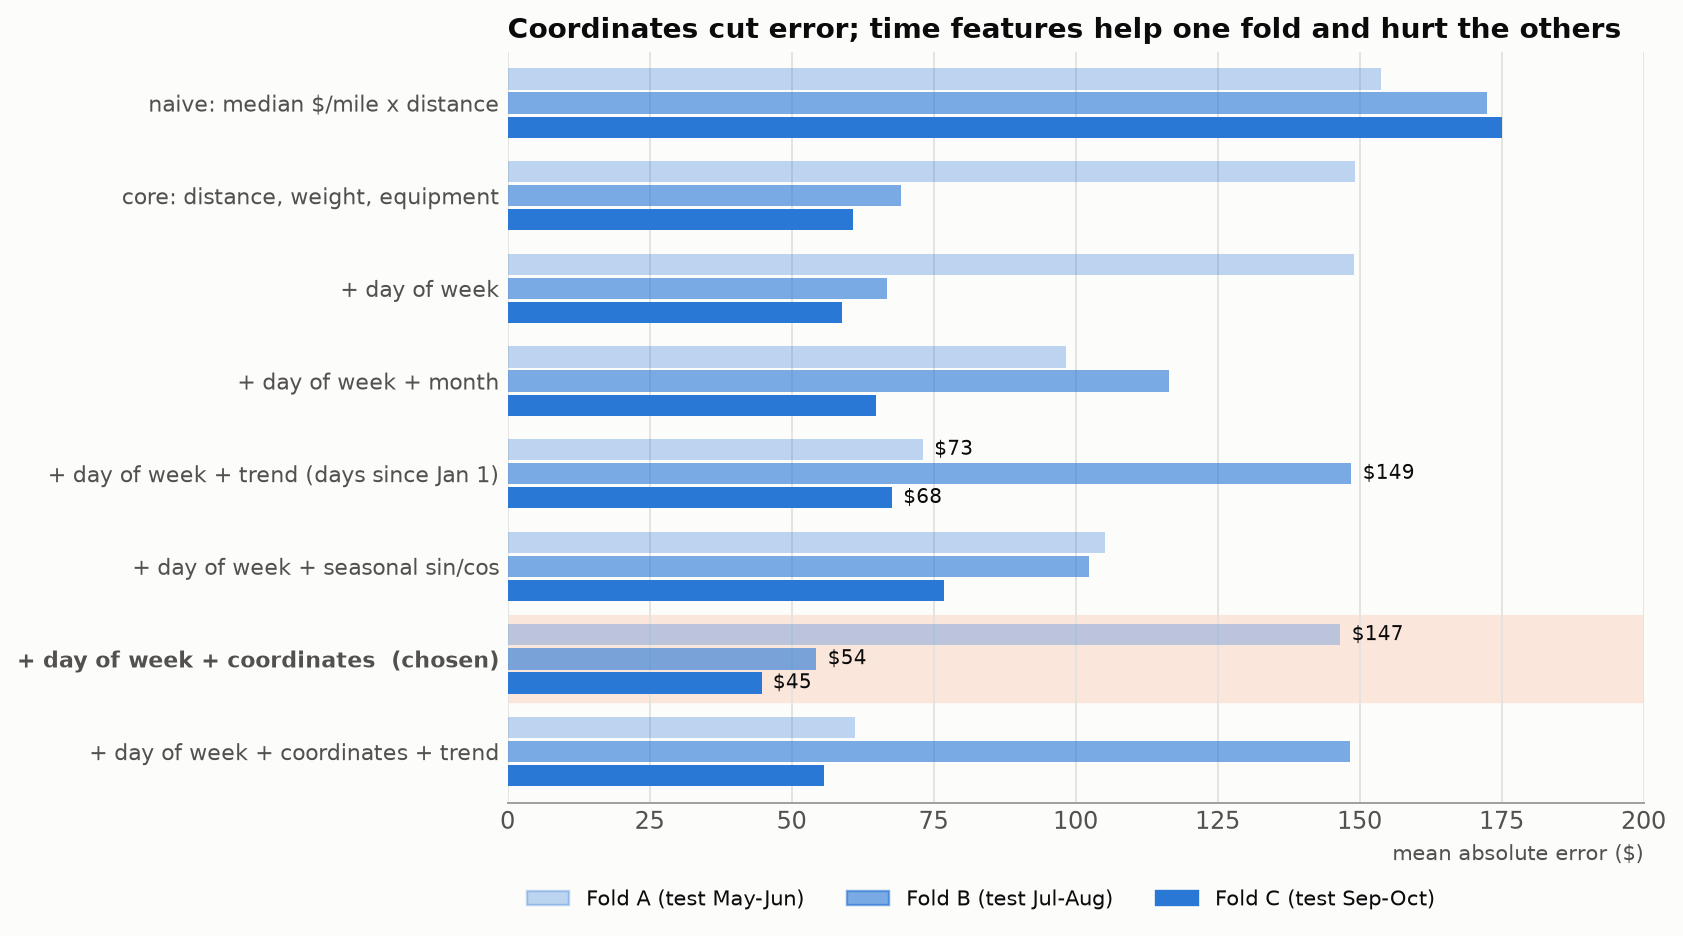

In [19]:
# Figure for the report: MAE of each feature set in each fold (folds are ordered in time -> one hue, light to dark)
folds_ = mae.loc[order, ["A", "B", "C"]]
shades = {"A": 0.30, "B": 0.62, "C": 1.0}
fold_text = {"A": "Fold A (test May-Jun)", "B": "Fold B (test Jul-Aug)", "C": "Fold C (test Sep-Oct)"}
n = len(order); h = 0.26
fig, ax = plt.subplots(figsize=(10, 5.6), dpi=170)
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
chosen_i = [i for i, k in enumerate(order) if "[chosen]" in k][0]
ax.axhspan(n - 1 - chosen_i - 0.46, n - 1 - chosen_i + 0.46, color="#fbe6dc", zorder=0)   # highlight the chosen row
label_rows = {chosen_i, order.index("+ day of week + trend (days since Jan 1)")}
for i, key in enumerate(order):
    yc = n - 1 - i
    for j, f in enumerate(["A", "B", "C"]):
        y = yc + (1 - j) * h
        v = folds_.loc[key, f]
        ax.barh(y, v, height=h * 0.88, color=BLUE, alpha=shades[f], zorder=2)
        if i in label_rows:
            ax.text(v + 2, y, f"${v:,.0f}", va="center", fontsize=8.5, color=INK)
ax.set_yticks(range(n)); ax.set_yticklabels([k.replace("   [chosen]", "  (chosen)") for k in order][::-1], fontsize=9.5, color=INK)
ax.get_yticklabels()[n - 1 - chosen_i].set_fontweight("bold")
ax.set_ylim(-0.55, n - 0.45); ax.set_xlim(0, 200); ax.tick_params(length=0, colors=MUTED)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=1); ax.set_axisbelow(True)
for s_ in ["top", "right", "left"]: ax.spines[s_].set_visible(False)
ax.spines["bottom"].set_color("#9d9c97")
ax.set_xlabel("mean absolute error ($)", color=MUTED, fontsize=9, loc="right")
ax.legend(handles=[mpatches.Patch(color=BLUE, alpha=shades[f], label=fold_text[f]) for f in "ABC"],
          loc="upper left", bbox_to_anchor=(0.0, -0.09), ncol=3, frameon=False, fontsize=9, labelcolor=INK)
ax.set_title("Coordinates cut error; time features help one fold and hurt the others", loc="left", fontsize=12, fontweight="bold", color=INK)
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "feature_ablation.png", bbox_inches="tight"); plt.show()

**Findings**

- **Coordinates are the one clear win.** Feature selection is based only on folds A and B: mean MAE falls from $107.8 (day of week only) to $100.5 with coordinates. Fold C is kept as a final check rather than being used to choose features.
- **Time features trade one fold for another.** A tree cannot extrapolate reliably, so month, trend, and seasonal terms help one period and hurt another. They are worse than the coordinate model on the A/B selection folds.
- With under one year of data we cannot tell a seasonal pattern from a market cycle, so neither is built into the model. The chosen model predicts the Jan-Oct average level; its main remaining risk is an unseen market-level shift.
- Every model beats the naive $/mile baseline by a wide margin.
- Each fold now fits the weight imputation and label-outlier rule on historical rows only. Corrupted labels are excluded only from metric reporting, not from the feature or prediction path of the test period.

## 5. Do coordinates generalise to cities the model has never seen?

Validation contains 8 cities that are not in train (12% of its rows), so this matters. Test: remove 8 random
cities (every load touching them) from the Jan-Aug training data, then score Sep-Oct loads that touch them.
Repeated with 6 random draws.

In [20]:
early_raw = train_raw[train_raw.date < "2025-09-01"]
late_raw = train_raw[train_raw.date >= "2025-09-01"]
all_cities = sorted(set(train_raw.pickup) | set(train_raw.delivery))
rng = np.random.default_rng(0)

rows = []
for rep in range(6):
    hidden = set(rng.choice(all_cities, 8, replace=False))
    raw_a = early_raw[~early_raw.pickup.isin(hidden) & ~early_raw.delivery.isin(hidden)]
    raw_b = late_raw[late_raw.pickup.isin(hidden) | late_raw.delivery.isin(hidden)]
    keep = ~raw_b["load_id"].isin(bad_ids).to_numpy()
    for label, groups in [("no geography", ("dow",)), ("with coordinates", ("dow", "coords"))]:
        predictions = fit_predict(raw_a, raw_b, groups)
        rows.append({"rep": rep, "model": label, "test rows": int(keep.sum()),
                     **ev.metrics(raw_b.loc[keep, config.TARGET], predictions[keep])})

unseen = pd.DataFrame(rows)
unseen.groupby("model")[["MAE", "MAPE_%", "bias_%"]].mean().round(2).loc[["no geography", "with coordinates"]]

,MAE,MAPE_%,bias_%
model,,,
no geography,63.99,2.91,-1.08
with coordinates,49.37,2.10,-0.66


In [10]:
new_cities = sorted((set(val.pickup) | set(val.delivery)) - set(all_cities))
print("cities only in validation:", new_cities)
print()
print("their coordinates vs the range seen in training:")
rng_tbl = pd.DataFrame({"train min": [city_table.loc[all_cities, "lat"].min(), city_table.loc[all_cities, "lon"].min()],
                        "train max": [city_table.loc[all_cities, "lat"].max(), city_table.loc[all_cities, "lon"].max()]}, index=["lat", "lon"])
print(rng_tbl.round(2))
print(city_table.loc[new_cities].round(2))

cities only in validation: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']

their coordinates vs the range seen in training:
     train min  train max
lat      28.36       44.3
lon    -121.70      -69.5
             lat     lon
city                    
Allentown  40.02  -73.81
Charlotte  34.65  -81.47
Chicago    40.51  -86.87
Jackson    32.08  -90.93
Knoxville  36.26  -86.03
Laredo     25.50  -97.23
Norfolk    37.12  -75.87
San Diego  32.01 -116.90


**Finding:** with 8 cities hidden from training, the loads touching them are predicted with MAE 64.0 without geography and 49.4 with coordinates (-23%), almost the same gain as for seen cities. The coordinates act as a map, so a new city is priced like its neighbours and no city or lane IDs are needed. Seven of the 8 new validation cities lie inside the coordinate range of the training cities; Laredo is slightly south of all of them (latitude 25.5 against a training minimum of 28.4) and will be treated like the southernmost training cities.

## 6. Final feature set on the main holdout, with and without the corrupted rows

Train on Jan-Aug, test on Sep-Oct. The 677 corrupted rows were removed from training, but the real validation
labels probably contain similar ones, so we also report what the error looks like if they are in the test set.

In [18]:
raw_a = train_raw[train_raw.date < config.HOLDOUT_START]
raw_b = train_raw[train_raw.date >= config.HOLDOUT_START]
a, b, flagged = prepare_fold(raw_a, raw_b)
b_bad = outliers[outliers.date >= config.HOLDOUT_START]

pred_all = fit_predict(raw_a, raw_b, FINAL)
keep = ~raw_b["load_id"].isin(bad_ids).to_numpy()
pred_clean = pred_all[keep]
pred_bad = fit_predict(raw_a, b_bad, FINAL)

res = pd.DataFrame({
    "clean test rows only": ev.metrics(b.loc[keep].reset_index(drop=True)[config.TARGET], pred_clean),
    "test rows + corrupted rows": ev.metrics(
        np.r_[b.loc[keep].reset_index(drop=True)[config.TARGET], b_bad[config.TARGET]],
        np.r_[pred_clean, pred_bad]),
}).T
res.insert(0, "rows", [int(keep.sum()), int(keep.sum()) + len(b_bad)])
print("features:", list(F.build_features(a, FINAL).columns))
res.round(2)

features: ['distance', 'log_distance', 'weight', 'weight_missing', 'eq_Dry_Van', 'eq_Flatbed', 'eq_Reefer', 'dow', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon']


,rows,MAE,MAPE_%,RMSE,bias_%
clean test rows only,9379,44.71,1.97,66.16,-0.66
test rows + corrupted rows,9523,100.67,4.48,630.90,0.81


In [12]:
# where is the remaining error? by equipment and by distance band (clean rows)
err = pd.DataFrame({"equipment": b.equipment.values, "distance": b.distance.values,
                    "ape": np.abs(pred_clean - b[config.TARGET].values) / b[config.TARGET].values * 100})
print("MAPE % by equipment"); print(err.groupby("equipment").ape.mean().round(2).to_string()); print()
print("MAPE % by distance band")
print(err.groupby(pd.cut(err.distance, [0, 300, 600, 1000, 1500, 2200, 3500])).ape.mean().round(2).to_string())

MAPE % by equipment
equipment
Dry Van    1.79
Flatbed    2.41
Reefer     1.99

MAPE % by distance band
distance
(0, 300]        2.92
(300, 600]      1.97
(600, 1000]     1.85
(1000, 1500]    1.86
(1500, 2200]    1.82
(2200, 3500]    1.83


**Finding:** on the clean Sep-Oct holdout the model reaches MAE $44.5, MAPE 2.0%, RMSE $65.8, bias -0.7%. That is the error in a stable market. If the test labels also contain corrupted rates like the 144 flagged in Sep-Oct, MAE becomes $100.5 and RMSE $631, almost entirely because of those rows. Nothing can predict them, so Spotter's metric will probably look worse than the clean number here.

Error is highest on short hauls under 300 miles (MAPE 2.9% against 1.8-2.0% elsewhere) and on Flatbed (2.4% against 1.8% for Dry Van). Fold A shows what a market-level shift does (MAPE 5.9%), so expect the Nov-Dec error to land between the two depending on how the market moves.

## 7. Diagnostic only: what level should Nov-Dec sit at?

The holdout cannot tell us about November and December, because no model here has seen them. As a **diagnostic**
(`market_index` is *not* a model input) we look at how the monthly rate level relates to `market_index`, which is
published in validation.csv, to see whether Nov-Dec look unusual.

In [13]:
line = params["rate_line"]
tmp = train.merge(train_raw[["load_id", "market_index"]], on="load_id")
tmp["level"] = pp.log_rate_residual(tmp, line)           # log-rate relative to the distance/equipment line
monthly = tmp.groupby(tmp.date.dt.to_period("M")).agg(level=("level", "mean"), market_index=("market_index", "mean"))
slope, intercept = np.polyfit(monthly.market_index, monthly.level, 1)
corr = np.corrcoef(monthly.market_index, monthly.level)[0, 1]

val_mi = val_raw.groupby(val_raw.date.dt.to_period("M")).market_index.mean()
implied = (slope * val_mi + intercept).rename("implied level")
n = len(monthly); xs = monthly.market_index.to_numpy()
resid_sd = np.sqrt(((monthly.level - (slope * monthly.market_index + intercept)) ** 2).sum() / (n - 2))
se = resid_sd * np.sqrt(1 + 1 / n + (val_mi - xs.mean()) ** 2 / ((xs - xs.mean()) ** 2).sum())
print(monthly.round(4).assign(note=""))
print()
print(f"monthly correlation level~market_index: {corr:.2f}  (10 points only)")
print("training average level:", round(tmp.level.mean(), 4))
print("implied Nov/Dec level from validation market_index:")
print(pd.concat([val_mi.rename("validation market_index"), implied, se.rename("std. error")], axis=1).round(4).to_string())

          level  market_index note
date                              
2025-01 -0.0552        0.9266     
2025-02 -0.0411        0.9959     
2025-03 -0.0047        1.0729     
2025-04 -0.0002        1.2073     
2025-05  0.0230        1.3014     
2025-06  0.0464        1.2803     
2025-07  0.0180        1.2011     
2025-08 -0.0126        0.9814     
2025-09  0.0046        0.8931     
2025-10  0.0069        0.9573     

monthly correlation level~market_index: 0.69  (10 points only)
training average level: -0.0011
implied Nov/Dec level from validation market_index:
         validation market_index  implied level  std. error
date                                                       
2025-11                   0.9187        -0.0232      0.0254
2025-12                   0.9347        -0.0211      0.0252


**Finding:** the monthly rate level tracks `market_index` (r = 0.69 over 10 months). validation.csv has a Nov market_index of 0.92 and a Dec value of 0.93, close to the Jan (0.93) and Sep (0.89) readings, which implies a Nov-Dec level about **2.3% below the Jan-Oct average, with a standard error of about 2.5%**. That is weak evidence: it cannot be told apart from "no change", and the model, which has no time or market feature, predicts the Jan-Oct average level. So the main known risk for the Nov-Dec predictions and the December chart is a level that is perhaps 0 to 5% too high. This estimate is not used to adjust any prediction.

## 8. Decisions carried into phase 3

- **Split:** expanding windows A/B/C, main holdout C (train Jan-Aug, test Sep-Oct); final fit on all of Jan-Oct.
- **Features:** `distance`, `log_distance`, `weight`, `weight_missing`, equipment one-hot, `dow`, four coordinate columns.
- **Target:** `log(posted_rate)`, predictions exponentiated (always positive, as the scorer requires).
- **Not used:** month / trend / seasonal terms, city or lane identity, `market_index`, `quote_signal`.

In [13]:
decisions = {
    "feature_groups": list(config.FINAL_FEATURE_GROUPS),
    "columns": list(X_train.columns),
    "target": "log(posted_rate)",
    "main_holdout": {"train": "2025-01-01..2025-08-31", "test": "2025-09-01..2025-10-31"},
}
(ROOT / "reports" / "phase2_decisions.json").write_text(json.dumps(decisions, indent=2))
decisions

{'feature_groups': ['dow', 'coords'],
 'columns': ['distance',
  'log_distance',
  'weight',
  'weight_missing',
  'eq_Dry_Van',
  'eq_Flatbed',
  'eq_Reefer',
  'dow',
  'pickup_lat',
  'pickup_lon',
  'delivery_lat',
  'delivery_lon'],
 'target': 'log(posted_rate)',
 'main_holdout': {'train': '2025-01-01..2025-08-31',
  'test': '2025-09-01..2025-10-31'}}